In [129]:
import importlib

import numpy.random

import velocity_model
import torch
from matplotlib import pyplot

L = 5e6
v0 = 1e3
Tr = L/(2*v0)
origins = torch.tensor([2e6, 4e6], dtype=torch.int32)
h_tgrid = torch.linspace(0, 1.1, steps=11, dtype=torch.double)
g_xranges_l = torch.tensor([1e6, 4.5e6], dtype=torch.int32)
g_xranges_u = torch.tensor([1.1e6, 4.6e6], dtype=torch.int32)

In [130]:
importlib.reload(velocity_model)
m = velocity_model.VelocityModel(L, True, origins, h_tgrid, g_xranges_l, g_xranges_u)

m.h_log = torch.nn.Parameter(torch.log(torch.tensor([1, 1, 1.5, 2, 1.5, 1, 0.5, 0.1, 0.5, 1, 1], dtype=torch.double)))
m.g_log = torch.nn.Parameter(torch.log(torch.tensor([10,0.1], dtype=torch.double)))
print(m.v0.dtype)
print(m.g_log.dtype)

torch.float64
torch.float64


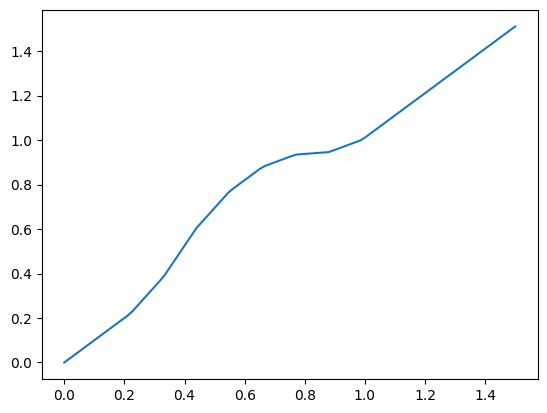

In [131]:
t = torch.linspace(0, 1.5, steps=100)
pyplot.plot(t, m.H(t).detach().numpy())


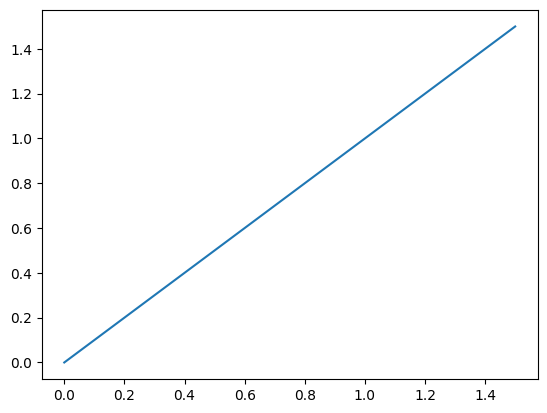

In [132]:
t = torch.linspace(0, 1.5, steps=100)
pyplot.plot(t, m.Hinv(m.H(t)).detach().numpy())

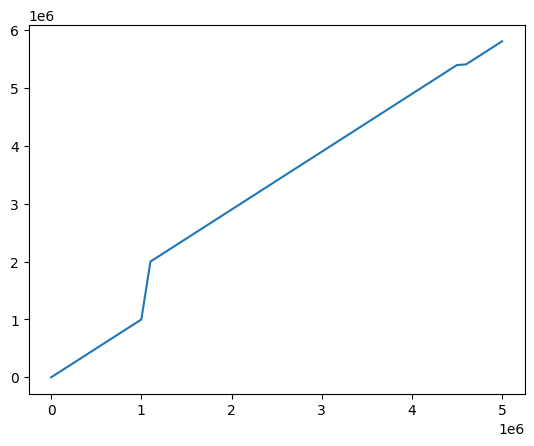

In [133]:
x = torch.linspace(0, L, steps=1000)
pyplot.plot(x, m.G_0(x).detach().numpy())

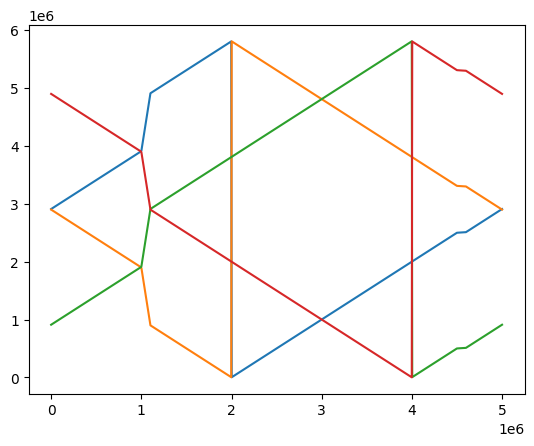

In [134]:
g1f = m.G(x, m.origins[0], torch.tensor([+1.0])).detach().numpy()
g1r = m.G(x, m.origins[0], torch.tensor([-1.0])).detach().numpy()
g2f = m.G(x, m.origins[1], torch.tensor([+1.0])).detach().numpy()
g2r = m.G(x, m.origins[1], torch.tensor([-1.0])).detach().numpy()
pyplot.plot(x, g1f, label="origin 1 fwd")
pyplot.plot(x, g1r, label="origin 1 rev")
pyplot.plot(x, g2f, label="origin 2 fwd")
pyplot.plot(x, g2r, label="origin 2 rev")

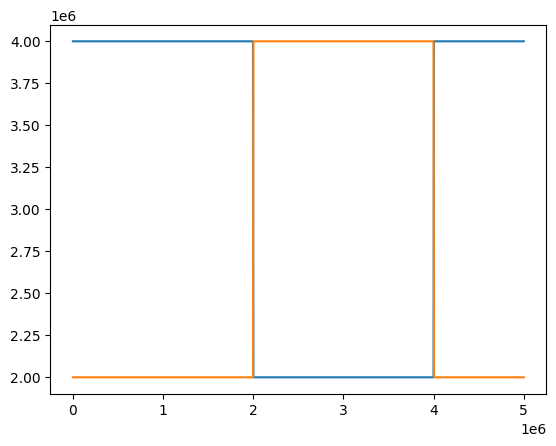

In [135]:
(i_l, i_r) = m.surrounding_origins(x)
pyplot.plot(x, m.origins[i_l], label="left")
pyplot.plot(x, m.origins[i_r], label="right")

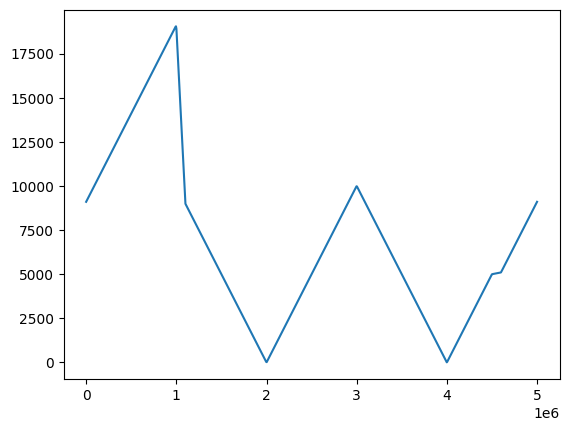

In [136]:
t = m.T(x).detach().numpy()
pyplot.plot(x, t)

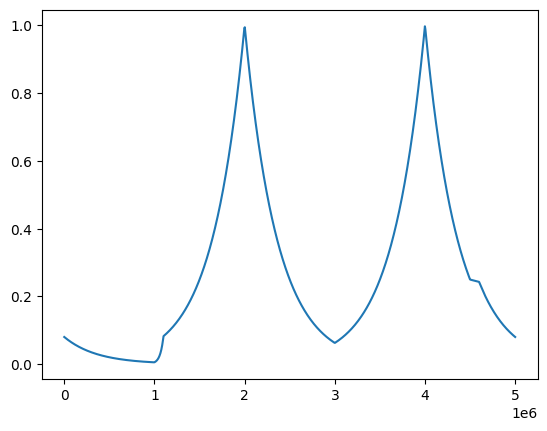

In [137]:
p = m.P(x).detach().numpy()
pyplot.plot(x, p)

In [138]:
coverage = 1e3
y_obs = torch.poisson(m.P(x) * coverage)
s_obs = torch.sqrt(y_obs)

l = velocity_model.VelocityModelLoss(x, y_obs, s_obs, m)
print(torch.sqrt(2 * (l() - m.penalty()) / x.size()[0]))

tensor([1.0521], dtype=torch.float64, grad_fn=<SqrtBackward0>)


In [139]:
optimizer = torch.optim.SGD(m.parameters())
loss = l()
print(loss)
optimizer.zero_grad()
loss.backward(retain_graph=True)
print(m.h_log)
print(m.h_log.grad)
optimizer.step()
print(m.h_log)


tensor([33732.4768], dtype=torch.float64, grad_fn=<AddBackward0>)
Parameter containing:
tensor([ 0.0000,  0.0000,  0.4055,  0.6931,  0.4055,  0.0000, -0.6931, -2.3026,
        -0.6931,  0.0000,  0.0000], dtype=torch.float64, requires_grad=True)
tensor([-5.9985e-07, -4.0547e+03,  1.1778e+03,  5.7536e+03,  1.1778e+03,
         2.8768e+03,  9.1629e+03, -3.2189e+04,  9.1629e+03,  6.9315e+03,
                nan], dtype=torch.float64)
Parameter containing:
tensor([ 5.9985e-10,  4.0547e+00, -7.7236e-01, -5.0605e+00, -7.7236e-01,
        -2.8768e+00, -9.8561e+00,  2.9886e+01, -9.8561e+00, -6.9315e+00,
                nan], dtype=torch.float64, requires_grad=True)
